<a href="https://colab.research.google.com/github/aghosh92/DevFest_Chennai_2026/blob/main/Notebooks/Notebook_II_Mat_Proj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Predicting Semiconductor Bandgaps via $\Delta$-Learning
### AI for Physical Sciences — Computational Materials Informatics


#### Prepared by: Lakhsumika K B
M.Sc. Physics, Department of Physics, IIT Madras

#### Mentor: Ayana Ghosh, Contact: ghosha@iitm.ac.in


## Data extraction

Downloading the experimental bandgap data from matminer

In [ ]:
from matminer.datasets import load_dataset

# Load the experimental bandgap dataset
df = load_dataset("expt_gap")

print(df.head())

        formula  gap expt
0  Hg0.7Cd0.3Te      0.35
1          CuBr      3.08
2           LuP      1.30
3      Cu3SbSe4      0.40
4           ZnO      3.44


Valid data

In [ ]:
# Drop rows where 'gap expt' is 0 or null
df = df[df["gap expt"] > 0].reset_index(drop=True)
print(len(df))

3896


In [ ]:
df.to_csv('expt_bandgap_data.csv')

In [ ]:
df.head()

,formula,gap expt
0,Hg0.7Cd0.3Te,0.35
1,CuBr,3.08
2,LuP,1.30
3,Cu3SbSe4,0.40
4,ZnO,3.44


Downloading the bandgap from the materials project database

In [ ]:
import numpy as np
from mp_api.client import MPRester

API_KEY = "YOUR_API_KEY"

dft_gaps = []
mp_ids = []

with MPRester(API_KEY,mute_progress_bars=True) as mpr:
    for formula in df["formula"]:
        try:
            docs = mpr.materials.summary.search(
                formula=formula,
                fields=["material_id", "band_gap"]
            )
            if docs:
                mp_ids.append(str(docs[0].material_id))
                dft_gaps.append(docs[0].band_gap)
            else:
                mp_ids.append(np.nan)
                dft_gaps.append(np.nan)
        except Exception:
            mp_ids.append(np.nan)
            dft_gaps.append(np.nan)

df["mp_id"] = mp_ids
df["gap_dft"] = dft_gaps

print(df.head())

        formula  gap expt       mp_id  gap_dft
0  Hg0.7Cd0.3Te      0.35         NaN      NaN
1          CuBr      3.08    mp-22913   0.4871
2           LuP      1.30    mp-10192   0.0000
3      Cu3SbSe4      0.40  mp-1225801   0.0000
4           ZnO      3.44  mp-2346983   0.8378


In [ ]:
df = df[df["gap_dft"] > 0].reset_index(drop=True)
print(len(df))

2159


In [ ]:
df.to_csv('mp.csv')

In [ ]:
import pandas as pd
df = pd.read_csv('mp.csv')
df.head()

,Unnamed: 0,formula,gap expt,mp_id,gap_dft
0,0,CuBr,3.08,mp-22913,0.4871
1,1,ZnO,3.44,mp-2346983,0.8378
2,2,K2Cd3Te4,2.26,mp-18531,1.4380
3,3,Pb6B2CrO12,1.80,mp-1197022,1.8898
4,4,Sr2Be2B2O7,8.00,mp-556498,4.0817


In [ ]:
import pandas as pd

df = pd.read_csv("mp.csv")

removed_df = df.sample(n=150, random_state=42)

df_remaining = df.drop(removed_df.index).reset_index(drop=True)

df_remaining.to_csv("mp.csv", index=False)

removed_df.reset_index(drop=True).to_csv("mp_150.csv", index=False)

print(f"Original count:  {len(df)}")
print(f"Remaining count: {len(df_remaining)}")
print(f"Removed count:   {len(removed_df)}")

Original count:  2159
Remaining count: 2009
Removed count:   150


Magpie features (numbers that define a material)

In [ ]:
from matminer.featurizers.composition import ElementProperty

# Initialize the magpie preset
magpie = ElementProperty.from_preset("magpie")

# 1. Get the list of all feature names (132 features in total)
features = magpie.feature_labels()
print(f"Total features: {len(features)}\n")

# Print the first 10 feature names
print("Sample feature names:")
for name in features[:10]:
    print(f" - {name}")

Total features: 132

Sample feature names:
 - MagpieData minimum Number
 - MagpieData maximum Number
 - MagpieData range Number
 - MagpieData mean Number
 - MagpieData avg_dev Number
 - MagpieData mode Number
 - MagpieData minimum MendeleevNumber
 - MagpieData maximum MendeleevNumber
 - MagpieData range MendeleevNumber
 - MagpieData mean MendeleevNumber


In [ ]:
import pandas as pd

df_features = pd.DataFrame(features, columns=["Feature Name"])
print(df_features.to_string())

                             Feature Name
0               MagpieData minimum Number
1               MagpieData maximum Number
2                 MagpieData range Number
3                  MagpieData mean Number
4               MagpieData avg_dev Number
5                  MagpieData mode Number
6      MagpieData minimum MendeleevNumber
7      MagpieData maximum MendeleevNumber
8        MagpieData range MendeleevNumber
9         MagpieData mean MendeleevNumber
10     MagpieData avg_dev MendeleevNumber
11        MagpieData mode MendeleevNumber
12        MagpieData minimum AtomicWeight
13        MagpieData maximum AtomicWeight
14          MagpieData range AtomicWeight
15           MagpieData mean AtomicWeight
16        MagpieData avg_dev AtomicWeight
17           MagpieData mode AtomicWeight
18            MagpieData minimum MeltingT
19            MagpieData maximum MeltingT
20              MagpieData range MeltingT
21               MagpieData mean MeltingT
22            MagpieData avg_dev M

In [ ]:
df_features.to_csv('magpie_features.csv',index=False)

In [ ]:
import pandas as pd
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty

# 1. Load data
df = pd.read_csv("mp.csv")

# 2. Clean formulas and create Composition objects
df["formula_clean"] = df["formula"].astype(str).str.replace(",", ".", regex=False).str.strip()
df["composition"] = df["formula_clean"].apply(lambda x: Composition(x) if x else None)
df = df.dropna(subset=["composition"]).reset_index(drop=True)

print("Starting Magpie featurization...")
magpie = ElementProperty.from_preset("magpie")
df_features = magpie.featurize_dataframe(df[["composition"]], col_id="composition", ignore_errors=True)

# 3. Add identifiers and target variables
df_features = df_features.drop(columns=["composition"])
for col in ["gap expt", "gap_dft","formula","mp_id"]:
    if col in df.columns:
        df_features.insert(0, col, df[col])

if "gap expt" in df_features.columns and "gap_dft" in df_features.columns:
    df_features["delta"] = df_features["gap expt"] - df_features["gap_dft"]

# 4. Save to CSV
df_features.to_csv("mp_magpie_features.csv", index=False)
print(f"Done! Saved {len(df_features)} materials to mp_magpie_features.csv")

Starting Magpie featurization...


ElementProperty:   0%|          | 0/2009 [00:00<?, ?it/s]

Done! Saved 2009 materials to mp_magpie_features.csv


In [ ]:
magpie = pd.read_csv('mp_magpie_features.csv')
magpie.head()

,mp_id,formula,gap_dft,gap expt,MagpieData minimum Number,MagpieData maximum Number,MagpieData range Number,MagpieData mean Number,MagpieData avg_dev Number,MagpieData mode Number,...,MagpieData mean GSmagmom,MagpieData avg_dev GSmagmom,MagpieData mode GSmagmom,MagpieData minimum SpaceGroupNumber,MagpieData maximum SpaceGroupNumber,MagpieData range SpaceGroupNumber,MagpieData mean SpaceGroupNumber,MagpieData avg_dev SpaceGroupNumber,MagpieData mode SpaceGroupNumber,delta
0,mp-22913,CuBr,0.4871,3.08,29.0,35.0,6.0,32.000000,3.000000,29.0,...,0.0,0.0,0.0,64.0,225.0,161.0,144.500000,80.500000,64.0,2.5929
1,mp-2346983,ZnO,0.8378,3.44,8.0,30.0,22.0,19.000000,11.000000,8.0,...,0.0,0.0,0.0,12.0,194.0,182.0,103.000000,91.000000,12.0,2.6022
2,mp-18531,K2Cd3Te4,1.4380,2.26,19.0,52.0,33.0,43.333333,10.814815,52.0,...,0.0,0.0,0.0,152.0,229.0,77.0,183.111111,27.654321,152.0,0.8220
3,mp-1197022,Pb6B2CrO12,1.8898,1.80,5.0,82.0,77.0,29.619048,29.931973,8.0,...,0.0,0.0,0.0,12.0,229.0,217.0,97.857143,98.122449,12.0,-0.0898
4,mp-556498,Sr2Be2B2O7,4.0817,8.00,4.0,38.0,34.0,11.538462,8.142012,8.0,...,0.0,0.0,0.0,12.0,225.0,213.0,96.461538,90.958580,12.0,3.9183


In [ ]:
import pandas as pd
magpie_df = pd.read_csv('mp_magpie_features.csv')
magpie_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2009 entries, 0 to 2008
Columns: 137 entries, mp_id to delta
dtypes: float64(135), object(2)
memory usage: 2.1+ MB


In [ ]:
magpie_df.isnull().sum()

mp_id                                  0
formula                                0
gap_dft                                0
gap expt                               0
MagpieData minimum Number              0
                                      ..
MagpieData range SpaceGroupNumber      0
MagpieData mean SpaceGroupNumber       0
MagpieData avg_dev SpaceGroupNumber    0
MagpieData mode SpaceGroupNumber       0
delta                                  0
Length: 137, dtype: int64

## Model training

Assigning dependent and independent features

In [ ]:
import pandas as pd

df = pd.read_csv("mp_magpie_features.csv")

y = df["delta"]

metadata_to_drop = ["mp_id", "formula", "gap expt", "delta"]
feature_cols = [c for c in df.columns if c not in metadata_to_drop]

X = df[feature_cols]

print(f"Target (y) shape:   {y.shape}")
print(f"Features (X) shape: {X.shape}")

Target (y) shape:   (2009,)
Features (X) shape: (2009, 133)


Training on different models to get the best model

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

print(f"Dataset successfully split: {X_train.shape[0]} train rows, {X_test.shape[0]} test rows.")
print(f"Number of input features: {X_train.shape[1]}")

# Define Models

models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge Regression": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Lasso Regression": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=0.01, max_iter=2000))]),
    "K-Neighbors Regressor": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=5))]),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42, n_jobs=None)
}

# Train

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    # Train metrics
    y_train_pred = model.predict(X_train)
    train_r2 = r2_score(y_train, y_train_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_mse = mean_squared_error(y_train, y_train_pred)
    train_rmse = np.sqrt(train_mse)

    # Test metrics
    y_test_pred = model.predict(X_test)
    test_r2 = r2_score(y_test, y_test_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    test_rmse = np.sqrt(test_mse)

    # Detailed output per model
    print(f"==================== {name} ====================")
    print(f"  TRAIN -> R²: {train_r2:.4f} | MAE: {train_mae:.4f} eV | MSE: {train_mse:.4f} | RMSE: {train_rmse:.4f} eV")
    print(f"  TEST  -> R²: {test_r2:.4f} | MAE: {test_mae:.4f} eV | MSE: {test_mse:.4f} | RMSE: {test_rmse:.4f} eV\n")

    results.append({
        "Model": name,
        "Train R²": round(train_r2, 4),
        "Test R²": round(test_r2, 4),
        "Train MAE": round(train_mae, 4),
        "Test MAE": round(test_mae, 4),
        "Train MSE": round(train_mse, 4),
        "Test MSE": round(test_mse, 4),
        "Train RMSE": round(train_rmse, 4),
        "Test RMSE": round(test_rmse, 4)
    })


summary_df = pd.DataFrame(results).sort_values(by="Test R²", ascending=False).reset_index(drop=True)

print("=" * 78)
print("                           MODEL COMPARISON SUMMARY")
print("=" * 78)
print(summary_df[["Model", "Train R²", "Test R²", "Train MAE", "Test MAE", "Test RMSE"]].to_string(index=False))

best_model_name = summary_df.iloc[0]["Model"]
best_test_r2 = summary_df.iloc[0]["Test R²"]
best_test_mae = summary_df.iloc[0]["Test MAE"]

print("\n" + "*" * 50)
print(f"🏆 Best Model: {best_model_name}")
print(f"   Test R²:    {best_test_r2:.4f}")
print(f"   Test MAE:   {best_test_mae:.4f} eV")
print("*" * 50)

Dataset successfully split: 1607 train rows, 402 test rows.
Number of input features: 133
==================== Linear Regression ====================
  TRAIN -> R²: 0.6204 | MAE: 0.4500 eV | MSE: 0.3847 | RMSE: 0.6202 eV
  TEST  -> R²: 0.5303 | MAE: 0.5065 eV | MSE: 0.5411 | RMSE: 0.7356 eV

==================== Ridge Regression ====================
  TRAIN -> R²: 0.6179 | MAE: 0.4512 eV | MSE: 0.3872 | RMSE: 0.6223 eV
  TEST  -> R²: 0.5506 | MAE: 0.4958 eV | MSE: 0.5178 | RMSE: 0.7196 eV

==================== Lasso Regression ====================
  TRAIN -> R²: 0.5535 | MAE: 0.4896 eV | MSE: 0.4525 | RMSE: 0.6727 eV
  TEST  -> R²: 0.4958 | MAE: 0.5283 eV | MSE: 0.5809 | RMSE: 0.7621 eV

==================== K-Neighbors Regressor ====================
  TRAIN -> R²: 0.7120 | MAE: 0.3319 eV | MSE: 0.2919 | RMSE: 0.5403 eV
  TEST  -> R²: 0.5522 | MAE: 0.4126 eV | MSE: 0.5159 | RMSE: 0.7183 eV

==================== Decision Tree Regressor ====================
  TRAIN -> R²: 0.8103 | MAE: 0

Training the Random Forest Regressor
1. Hyper parameter tuning

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# 1. Parameter search grid
param_distributions = {
    "n_estimators": [100, 150, 200, 250, 300],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", 0.33, 0.5]
}

# 2. Base model
rf_base = RandomForestRegressor(
    criterion="squared_error",
    bootstrap=True,
    random_state=42,
    n_jobs=1
)

# 3. Randomized Search (multithreaded across all CPU cores)
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

# 4. Print only the winning parameters
print("=== BEST HYPERPARAMETERS ===")
for param, value in random_search.best_params_.items():
    print(f"{param}: {value}")

=== BEST HYPERPARAMETERS ===
n_estimators: 200
min_samples_split: 2
min_samples_leaf: 1
max_features: 1.0
max_depth: 25


Training the model with the best parameters

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tuned_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=25,
    max_features=1.0,
    min_samples_split=2,
    min_samples_leaf=1,
    criterion="squared_error",
    random_state=42,
    n_jobs=1
)


tuned_rf.fit(X_train, y_train)

# Predictions on training data
train_pred = tuned_rf.predict(X_train)
train_r2 = r2_score(y_train, train_pred)
train_mae = mean_absolute_error(y_train, train_pred)
train_mse = mean_squared_error(y_train, train_pred)
train_rmse = np.sqrt(train_mse)

# Predictions on test data
test_pred = tuned_rf.predict(X_test)
test_r2 = r2_score(y_test, test_pred)
test_mae = mean_absolute_error(y_test, test_pred)
test_mse = mean_squared_error(y_test, test_pred)
test_rmse = np.sqrt(test_mse)

# Results
print("=" * 60)
print("             FINAL MODEL EVALUATION (RESIDUAL Δ)")
print("=" * 60)
print(f" TRAIN -> R²: {train_r2:.4f} | MAE: {train_mae:.4f} eV | MSE: {train_mse:.4f} | RMSE: {train_rmse:.4f} eV")
print(f" TEST  -> R²: {test_r2:.4f} | MAE: {test_mae:.4f} eV | MSE: {test_mse:.4f} | RMSE: {test_rmse:.4f} eV")
print("=" * 60)

             FINAL MODEL EVALUATION (RESIDUAL Δ)
 TRAIN -> R²: 0.9598 | MAE: 0.1348 eV | MSE: 0.0407 | RMSE: 0.2018 eV
 TEST  -> R²: 0.7503 | MAE: 0.2908 eV | MSE: 0.2877 | RMSE: 0.5364 eV


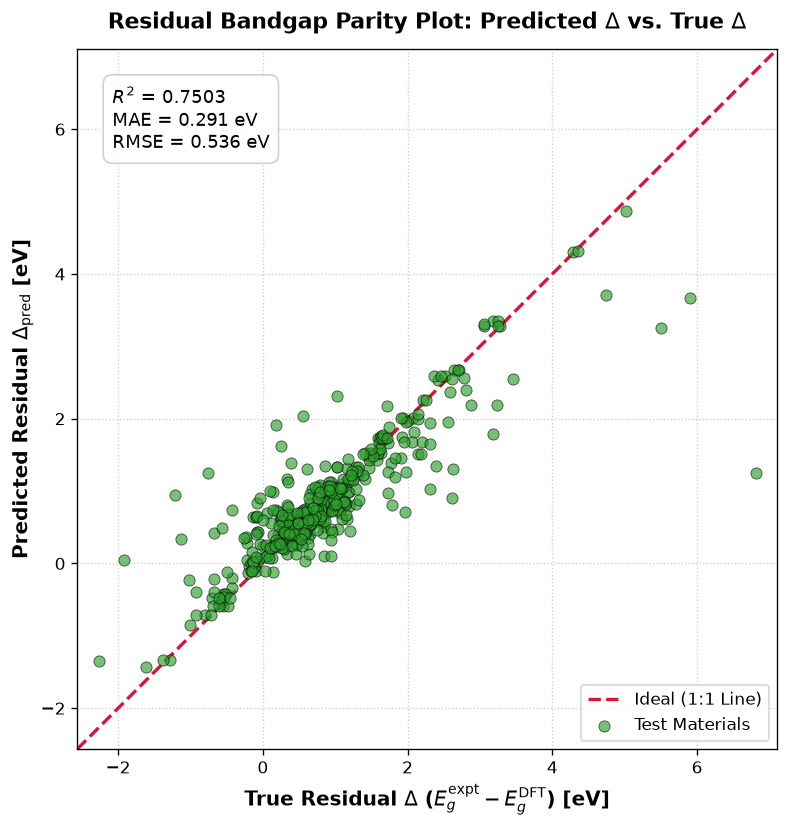

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# True residual: Δ_true = E_g(expt) - E_g(DFT)
y_true_delta = y_test.values if hasattr(y_test, "values") else np.array(y_test)

# Predict residual correction using your trained model (tuned_rf or model)
try:
    y_pred_delta = tuned_rf.predict(X_test)
except NameError:
    y_pred_delta = model.predict(X_test)


r2_delta = r2_score(y_true_delta, y_pred_delta)
mae_delta = mean_absolute_error(y_true_delta, y_pred_delta)
rmse_delta = np.sqrt(mean_squared_error(y_true_delta, y_pred_delta))

plt.figure(figsize=(7, 7), dpi=120)

min_bound = min(np.min(y_true_delta), np.min(y_pred_delta)) - 0.3
max_bound = max(np.max(y_true_delta), np.max(y_pred_delta)) + 0.3

plt.plot(
    [min_bound, max_bound],
    [min_bound, max_bound],
    color="crimson",
    linestyle="--",
    linewidth=2,
    label="Ideal (1:1 Line)",
    zorder=2,
)

plt.scatter(
    y_true_delta,
    y_pred_delta,
    alpha=0.65,
    edgecolors="k",
    linewidths=0.5,
    c="#2ca02c",
    s=45,
    label="Test Materials",
    zorder=3,
)

plt.xlabel(r"True Residual $\Delta$ ($E_g^{\mathrm{expt}} - E_g^{\mathrm{DFT}}$) [eV]", fontsize=12, fontweight="bold")
plt.ylabel(r"Predicted Residual $\Delta_{\mathrm{pred}}$ [eV]", fontsize=12, fontweight="bold")
plt.title(r"Residual Bandgap Parity Plot: Predicted $\Delta$ vs. True $\Delta$", fontsize=13, fontweight="bold", pad=12)

plt.xlim(min_bound, max_bound)
plt.ylim(min_bound, max_bound)
plt.gca().set_aspect("equal", adjustable="box")

metrics_text = (
    f"$R^2$ = {r2_delta:.4f}\n"
    f"MAE = {mae_delta:.3f} eV\n"
    f"RMSE = {rmse_delta:.3f} eV"
)
plt.gca().text(
    0.05,
    0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc", alpha=0.9),
)

plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

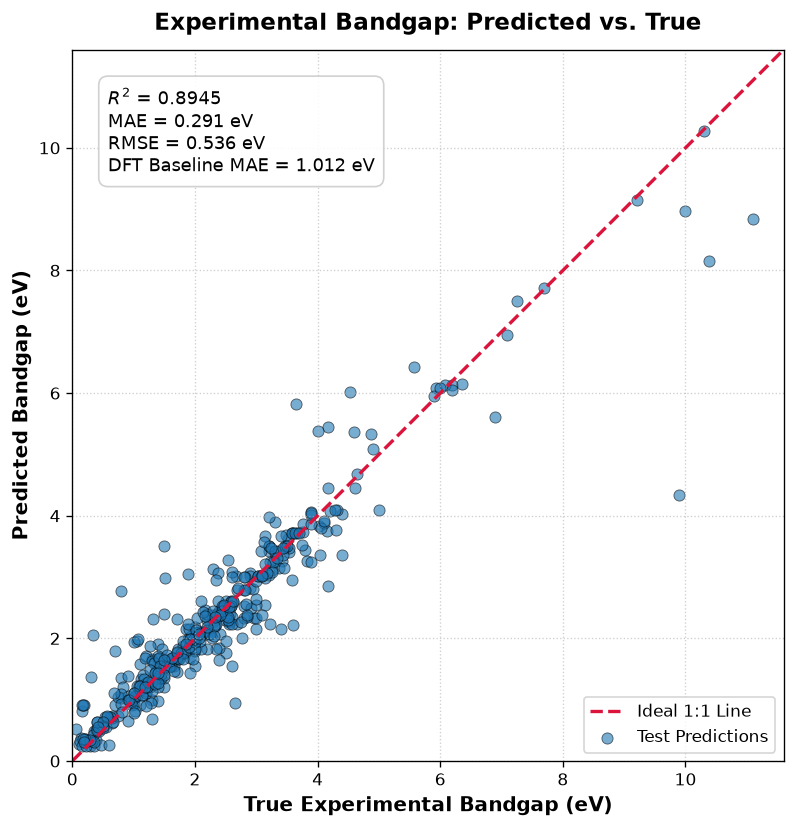

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Compute Reconstructed Bandgap Predictions for the Test Set

# E_pred = E_dft + Δ_pred
test_delta_pred = tuned_rf.predict(X_test)
test_dft_gap = X_test["gap_dft"].values
y_true_expt = df.loc[X_test.index, "gap expt"].values
y_pred_expt = np.clip(test_dft_gap + test_delta_pred, a_min=0.0, a_max=None)

# 2. Calculate Evaluation Metrics

r2 = r2_score(y_true_expt, y_pred_expt)
mae = mean_absolute_error(y_true_expt, y_pred_expt)
rmse = np.sqrt(mean_squared_error(y_true_expt, y_pred_expt))

# Baseline DFT error for comparison
dft_mae = mean_absolute_error(y_true_expt, test_dft_gap)

# 3. Generate Predicted vs. True Parity Plot

plt.figure(figsize=(7, 7), dpi=120)


max_val = max(np.max(y_true_expt), np.max(y_pred_expt)) + 0.5
min_val = 0.0

# Plot 1:1 reference line (ideal prediction)
plt.plot(
    [min_val, max_val], [min_val, max_val],
    color="crimson",
    linestyle="--",
    linewidth=2,
    label="Ideal 1:1 Line"
)

# Plot test set predictions
plt.scatter(
    y_true_expt,
    y_pred_expt,
    alpha=0.6,
    edgecolors="k",
    linewidths=0.5,
    c="#1f77b4",
    s=45,
    label="Test Predictions"
)

plt.xlabel("True Experimental Bandgap (eV)", fontsize=12, fontweight="bold")
plt.ylabel("Predicted Bandgap (eV)", fontsize=12, fontweight="bold")
plt.title("Experimental Bandgap: Predicted vs. True", fontsize=14, fontweight="bold", pad=12)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)


stats_text = (
    f"$R^2$ = {r2:.4f}\n"
    f"MAE = {mae:.3f} eV\n"
    f"RMSE = {rmse:.3f} eV\n"
    f"DFT Baseline MAE = {dft_mae:.3f} eV"
)
plt.gca().text(
    0.05, 0.95,
    stats_text,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc", alpha=0.9)
)

plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", frameon=True)
plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

Predicting the Experimental bandgap for a material

In [ ]:
import numpy as np
import pandas as pd
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty

# 1. Load the holdout dataset (fallback to mp_removed_150.csv if needed)
df_150 = pd.read_csv("mp_150.csv")


# 2. Pick a material
sample = df_150.sample(n=9).copy()

# Extract identification and true values
formula = sample["formula"].values[0]
mp_id = sample["mp_id"].values[0] if "mp_id" in sample.columns else "N/A"
dft_gap = float(sample["gap_dft"].values[0])
true_expt_gap = float(sample["gap expt"].values[0])

# 3. Prepare features

sample["formula_clean"] = str(formula).replace(",", ".").strip()
sample["composition"] = sample["formula_clean"].apply(Composition)

magpie = ElementProperty.from_preset("magpie")
sample_feat = magpie.featurize_dataframe(sample, col_id="composition", ignore_errors=True)
X_sample = sample_feat[feature_cols]

# 4. Predict residual Δ and reconstruct the experimental bandgap
pred_delta = tuned_rf.predict(X_sample)[0]
pred_expt_gap = max(0.0, dft_gap + pred_delta)

# 5. Display results
dft_error = abs(true_expt_gap - dft_gap)
ml_error = abs(true_expt_gap - pred_expt_gap)

print("=" * 50)
print(f"Material:               {formula} ({mp_id})")
print("=" * 50)
print(f"Baseline DFT Gap:       {dft_gap:.3f} eV")
print(f"True Experimental Gap:  {true_expt_gap:.3f} eV")
print(f"ML Predicted Gap:       {pred_expt_gap:.3f} eV")
print("-" * 50)
print(f"Baseline DFT Error:     {dft_error:.3f} eV")
print(f"ML Prediction Error:    {ml_error:.3f} eV")
print(f"Error Reduction:        {dft_error - ml_error:+.3f} eV")
print("=" * 50)

ElementProperty:   0%|          | 0/9 [00:00<?, ?it/s]

Material:               Ba2In2Se5 (mp-573635)
Baseline DFT Gap:       1.395 eV
True Experimental Gap:  2.120 eV
ML Predicted Gap:       2.144 eV
--------------------------------------------------
Baseline DFT Error:     0.726 eV
ML Prediction Error:    0.024 eV
Error Reduction:        +0.701 eV
